<a href="https://colab.research.google.com/github/amnisymimi/sign-language-translation/blob/nuhaa-dev/features/nonmanual/P2_Facial_Feature_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Extract Facial Features

In [1]:
!pip uninstall -y mediapipe
!pip install -q mediapipe opencv-python-headless numpy pandas matplotlib scipy

Found existing installation: mediapipe 1.2.2
Uninstalling mediapipe-1.2.2:
  Successfully uninstalled mediapipe-1.2.2


In [2]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import urllib.request

from scipy.spatial.transform import Rotation
from google.colab import files

print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("NumPy:", np.__version__)

OpenCV: 4.14.0
MediaPipe: 1.2.2
NumPy: 2.4.6


In [3]:
uploaded = files.upload()
video_path = list(uploaded.keys())[0]
print("Video uploaded:", video_path)

Saving SXPAKOKS220760950.mp4 to SXPAKOKS220760950.mp4
Video uploaded: SXPAKOKS220760950.mp4


In [4]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps if fps > 0 else 0

print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration:", duration, "seconds")

cap.release()

if fps <= 0:
    raise ValueError("Could not read a valid FPS value from the uploaded video.")

FPS: 30.0
Total frames: 195
Duration: 6.5 seconds


In [5]:
model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/latest/"
    "face_landmarker.task"
)

model_path = "face_landmarker.task"
urllib.request.urlretrieve(model_url, model_path)

print("Face Landmarker model downloaded!")

Face Landmarker model downloaded!


In [6]:
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=RunningMode.VIDEO,
    output_face_blendshapes=True,
    output_facial_transformation_matrixes=True,
    num_faces=1
)

print("MediaPipe configured successfully!")

MediaPipe configured successfully!


In [7]:
results_data = []

cap = cv2.VideoCapture(video_path)

with FaceLandmarker.create_from_options(options) as landmarker:
    frame_index = 0

    while True:
        success, frame = cap.read()
        if not success:
            break

        timestamp_ms = int(frame_index * 1000 / fps)
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        result = landmarker.detect_for_video(mp_image, timestamp_ms)

        row = {
            "frame": frame_index,
            "timestamp_ms": timestamp_ms,
            "face_detected": len(result.face_landmarks) > 0
        }

        if result.face_landmarks:
            landmarks = result.face_landmarks[0]

            for i, point in enumerate(landmarks):
                row[f"landmark_{i}_x"] = point.x
                row[f"landmark_{i}_y"] = point.y
                row[f"landmark_{i}_z"] = point.z

            if result.face_blendshapes:
                for category in result.face_blendshapes[0]:
                    row[f"blendshape_{category.category_name}"] = category.score

        results_data.append(row)
        frame_index += 1

cap.release()

df = pd.DataFrame(results_data)

print("Extraction completed!")
print("Total frames:", len(df))
print("Frames with detected faces:", int(df["face_detected"].sum()))
print("Feature table shape:", df.shape)

display(df.head())

Extraction completed!
Total frames: 195
Frames with detected faces: 195
Feature table shape: (195, 1489)


,frame,timestamp_ms,face_detected,landmark_0_x,landmark_0_y,landmark_0_z,landmark_1_x,landmark_1_y,landmark_1_z,landmark_2_x,...,blendshape_mouthShrugLower,blendshape_mouthShrugUpper,blendshape_mouthSmileLeft,blendshape_mouthSmileRight,blendshape_mouthStretchLeft,blendshape_mouthStretchRight,blendshape_mouthUpperUpLeft,blendshape_mouthUpperUpRight,blendshape_noseSneerLeft,blendshape_noseSneerRight
0,0,0,True,0.502408,0.199802,-0.016936,0.500697,0.166287,-0.025364,0.500561,...,0.036547,0.010178,0.012799,0.053377,0.000273,0.005218,0.000104,0.000289,9.767026e-07,9.244729e-07
1,1,33,True,0.497741,0.207267,-0.014837,0.496767,0.178434,-0.023316,0.496786,...,0.562464,0.044468,0.000815,0.000618,0.006829,0.000537,0.000083,0.000240,2.174103e-07,3.114692e-07
2,2,66,True,0.496866,0.209560,-0.013808,0.496211,0.179092,-0.021430,0.496097,...,0.646304,0.024409,0.000018,0.000011,0.000707,0.000328,0.000016,0.000032,1.817935e-07,1.657577e-07
3,3,100,True,0.496795,0.210040,-0.013409,0.496276,0.179411,-0.020836,0.496119,...,0.660114,0.021514,0.000006,0.000003,0.000350,0.000403,0.000012,0.000018,2.239991e-07,1.864403e-07
4,4,133,True,0.496932,0.210078,-0.013342,0.496343,0.179231,-0.020740,0.496195,...,0.631193,0.019017,0.000006,0.000003,0.000333,0.000468,0.000010,0.000015,2.310858e-07,2.098289e-07


In [8]:
detection_rate = df["face_detected"].mean() * 100
print(f"Face detection rate: {detection_rate:.2f}%")

print("\nDetection counts:")
print(df["face_detected"].value_counts())

print("\nMissing values (top 10 columns):")
print(df.isna().sum().sort_values(ascending=False).head(10))

Face detection rate: 100.00%

Detection counts:
face_detected
True    195
Name: count, dtype: int64

Missing values (top 10 columns):
frame            0
timestamp_ms     0
face_detected    0
landmark_0_x     0
landmark_0_y     0
landmark_0_z     0
landmark_1_x     0
landmark_1_y     0
landmark_1_z     0
landmark_2_x     0
dtype: int64


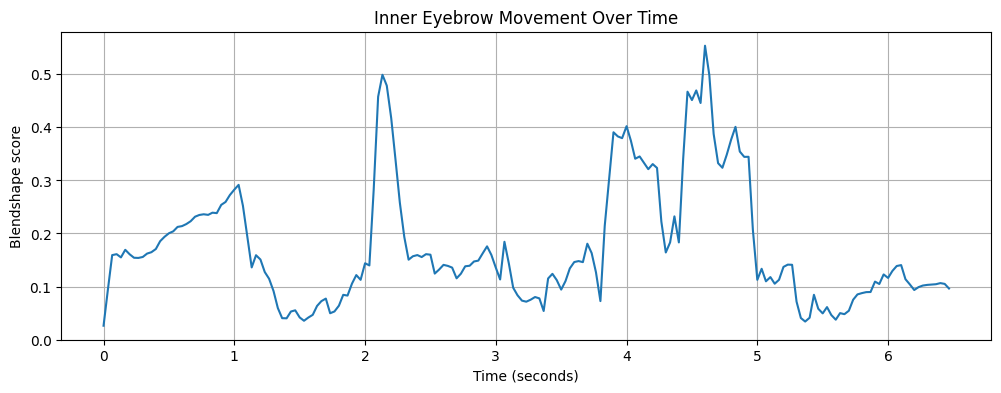

In [9]:
column = "blendshape_browInnerUp"

if column in df.columns:
    plt.figure(figsize=(12, 4))

    plt.plot(
        df["timestamp_ms"] / 1000,
        df[column]
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Blendshape score")
    plt.title("Inner Eyebrow Movement Over Time")
    plt.grid(True)
    plt.show()
else:
    print("Blendshape column not found.")

In [10]:
print([
    col for col in df.columns
    if "blendshape_" in col
])

['blendshape__neutral', 'blendshape_browDownLeft', 'blendshape_browDownRight', 'blendshape_browInnerUp', 'blendshape_browOuterUpLeft', 'blendshape_browOuterUpRight', 'blendshape_cheekPuff', 'blendshape_cheekSquintLeft', 'blendshape_cheekSquintRight', 'blendshape_eyeBlinkLeft', 'blendshape_eyeBlinkRight', 'blendshape_eyeLookDownLeft', 'blendshape_eyeLookDownRight', 'blendshape_eyeLookInLeft', 'blendshape_eyeLookInRight', 'blendshape_eyeLookOutLeft', 'blendshape_eyeLookOutRight', 'blendshape_eyeLookUpLeft', 'blendshape_eyeLookUpRight', 'blendshape_eyeSquintLeft', 'blendshape_eyeSquintRight', 'blendshape_eyeWideLeft', 'blendshape_eyeWideRight', 'blendshape_jawForward', 'blendshape_jawLeft', 'blendshape_jawOpen', 'blendshape_jawRight', 'blendshape_mouthClose', 'blendshape_mouthDimpleLeft', 'blendshape_mouthDimpleRight', 'blendshape_mouthFrownLeft', 'blendshape_mouthFrownRight', 'blendshape_mouthFunnel', 'blendshape_mouthLeft', 'blendshape_mouthLowerDownLeft', 'blendshape_mouthLowerDownRigh

In [11]:
df.to_csv("facial_features.csv", index=False)

df.to_numpy().shape

print("Facial features saved!")

Facial features saved!


In [12]:
files.download("facial_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("Total frames:", len(df))

print("\nDetection counts:")
print(df["face_detected"].value_counts())

print("\nDetection rate:")
print(df["face_detected"].mean() * 100)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))

Total frames: 195

Detection counts:
face_detected
True    195
Name: count, dtype: int64

Detection rate:
100.0

Missing values:
frame            0
timestamp_ms     0
face_detected    0
landmark_0_x     0
landmark_0_y     0
landmark_0_z     0
landmark_1_x     0
landmark_1_y     0
landmark_1_z     0
landmark_2_x     0
dtype: int64


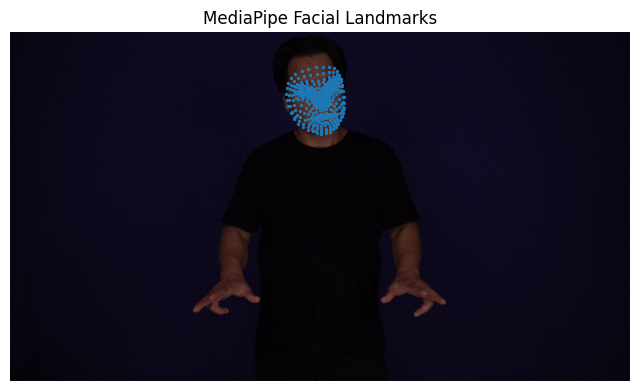

In [14]:
cap = cv2.VideoCapture(video_path)

# Select a frame where a face was detected
valid_frame = df[df["face_detected"] == True].iloc[50]
frame_number = int(valid_frame["frame"])

cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
success, frame = cap.read()

cap.release()

if success:
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(rgb)

    landmarks = [
        (valid_frame[f"landmark_{i}_x"],
         valid_frame[f"landmark_{i}_y"])
        for i in range(478)
    ]

    height, width = rgb.shape[:2]

    x = [p[0] * width for p in landmarks]
    y = [p[1] * height for p in landmarks]

    plt.scatter(x, y, s=2)
    plt.title("MediaPipe Facial Landmarks")
    plt.axis("off")
    plt.show()

In [15]:
blendshape_columns = [
    col for col in df.columns
    if col.startswith("blendshape_")
]

print("Number of blendshape features:", len(blendshape_columns))

for col in blendshape_columns:
    print(col)

Number of blendshape features: 52
blendshape__neutral
blendshape_browDownLeft
blendshape_browDownRight
blendshape_browInnerUp
blendshape_browOuterUpLeft
blendshape_browOuterUpRight
blendshape_cheekPuff
blendshape_cheekSquintLeft
blendshape_cheekSquintRight
blendshape_eyeBlinkLeft
blendshape_eyeBlinkRight
blendshape_eyeLookDownLeft
blendshape_eyeLookDownRight
blendshape_eyeLookInLeft
blendshape_eyeLookInRight
blendshape_eyeLookOutLeft
blendshape_eyeLookOutRight
blendshape_eyeLookUpLeft
blendshape_eyeLookUpRight
blendshape_eyeSquintLeft
blendshape_eyeSquintRight
blendshape_eyeWideLeft
blendshape_eyeWideRight
blendshape_jawForward
blendshape_jawLeft
blendshape_jawOpen
blendshape_jawRight
blendshape_mouthClose
blendshape_mouthDimpleLeft
blendshape_mouthDimpleRight
blendshape_mouthFrownLeft
blendshape_mouthFrownRight
blendshape_mouthFunnel
blendshape_mouthLeft
blendshape_mouthLowerDownLeft
blendshape_mouthLowerDownRight
blendshape_mouthPressLeft
blendshape_mouthPressRight
blendshape_mouthPu

In [17]:
selected_features = [
    # Eyebrows (5)
    "blendshape_browInnerUp",
    "blendshape_browDownLeft",
    "blendshape_browDownRight",
    "blendshape_browOuterUpLeft",
    "blendshape_browOuterUpRight",

    # Eyes (6)
    "blendshape_eyeBlinkLeft",
    "blendshape_eyeBlinkRight",
    "blendshape_eyeWideLeft",
    "blendshape_eyeWideRight",
    "blendshape_eyeSquintLeft",
    "blendshape_eyeSquintRight",

    # Mouth (7)
    "blendshape_jawOpen",
    "blendshape_mouthFunnel",
    "blendshape_mouthPucker",
    "blendshape_mouthSmileLeft",
    "blendshape_mouthSmileRight",
    "blendshape_mouthPressLeft",
    "blendshape_mouthPressRight"
]

# Keep only columns that were actually returned by MediaPipe.
available_features = [c for c in selected_features if c in df.columns]
missing_features = [c for c in selected_features if c not in df.columns]

if missing_features:
    print("Warning — these expected blendshapes were not found:", missing_features)

facial_df = df[
    ["frame", "timestamp_ms", "face_detected"] + available_features
].copy()

print("Selected blendshape count:", len(available_features))
print("Selected feature table shape:", facial_df.shape)
display(facial_df.head())

Selected blendshape count: 18
Selected feature table shape: (195, 21)


,frame,timestamp_ms,face_detected,blendshape_browInnerUp,blendshape_browDownLeft,blendshape_browDownRight,blendshape_browOuterUpLeft,blendshape_browOuterUpRight,blendshape_eyeBlinkLeft,blendshape_eyeBlinkRight,...,blendshape_eyeWideRight,blendshape_eyeSquintLeft,blendshape_eyeSquintRight,blendshape_jawOpen,blendshape_mouthFunnel,blendshape_mouthPucker,blendshape_mouthSmileLeft,blendshape_mouthSmileRight,blendshape_mouthPressLeft,blendshape_mouthPressRight
0,0,0,True,0.026162,0.000368,0.086939,0.686218,0.007839,0.084780,0.525877,...,0.000475,0.716166,0.018116,0.021079,0.000323,0.000730,0.012799,0.053377,0.156517,0.621088
1,1,33,True,0.093760,0.015091,0.011320,0.070378,0.031080,0.455023,0.463987,...,0.000426,0.447087,0.177701,0.028245,0.000098,0.000799,0.000815,0.000618,0.143303,0.151159
2,2,66,True,0.159248,0.009599,0.005767,0.090608,0.040310,0.393674,0.397619,...,0.000720,0.322467,0.281019,0.050360,0.000090,0.008829,0.000018,0.000011,0.036902,0.052354
3,3,100,True,0.161017,0.008226,0.004930,0.105301,0.051751,0.347290,0.367081,...,0.000837,0.331381,0.319437,0.059109,0.000093,0.019325,0.000006,0.000003,0.029136,0.036000
4,4,133,True,0.154933,0.008090,0.005287,0.109267,0.053804,0.331615,0.358266,...,0.000837,0.340857,0.335343,0.060909,0.000089,0.019368,0.000006,0.000003,0.029352,0.036500


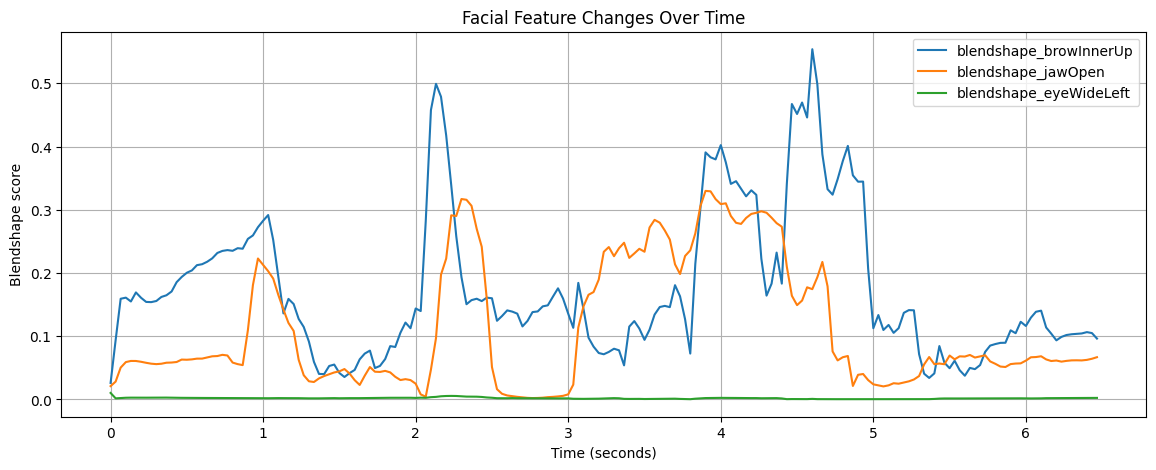

In [18]:
plt.figure(figsize=(14, 5))

for feature in [
    "blendshape_browInnerUp",
    "blendshape_jawOpen",
    "blendshape_eyeWideLeft"
]:
    plt.plot(
        facial_df["timestamp_ms"] / 1000,
        facial_df[feature],
        label=feature
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Blendshape score")
plt.title("Facial Feature Changes Over Time")
plt.legend()
plt.grid()
plt.show()

In [19]:
facial_df.to_csv(
    "selected_facial_features.csv",
    index=False
)

print("Saved selected facial features!")

Saved selected facial features!


# Extract Temporal Features

In [20]:
temporal_df = facial_df.copy()

blendshape_columns = [
    col for col in temporal_df.columns
    if col.startswith("blendshape_")
]

time_diff = temporal_df["timestamp_ms"].diff() / 1000

for col in blendshape_columns:
    temporal_df[f"{col}_delta"] = temporal_df[col].diff() / time_diff

display(temporal_df.head())

,frame,timestamp_ms,face_detected,blendshape_browInnerUp,blendshape_browDownLeft,blendshape_browDownRight,blendshape_browOuterUpLeft,blendshape_browOuterUpRight,blendshape_eyeBlinkLeft,blendshape_eyeBlinkRight,...,blendshape_eyeWideRight_delta,blendshape_eyeSquintLeft_delta,blendshape_eyeSquintRight_delta,blendshape_jawOpen_delta,blendshape_mouthFunnel_delta,blendshape_mouthPucker_delta,blendshape_mouthSmileLeft_delta,blendshape_mouthSmileRight_delta,blendshape_mouthPressLeft_delta,blendshape_mouthPressRight_delta
0,0,0,True,0.026162,0.000368,0.086939,0.686218,0.007839,0.084780,0.525877,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,33,True,0.093760,0.015091,0.011320,0.070378,0.031080,0.455023,0.463987,...,-0.001496,-8.153893,4.835909,0.217155,-0.006836,0.002077,-0.363136,-1.598757,-0.400408,-14.240289
2,2,66,True,0.159248,0.009599,0.005767,0.090608,0.040310,0.393674,0.397619,...,0.008909,-3.776374,3.130858,0.670140,-0.000215,0.243335,-0.024158,-0.018382,-3.224265,-2.994072
3,3,100,True,0.161017,0.008226,0.004930,0.105301,0.051751,0.347290,0.367081,...,0.003427,0.262176,1.129935,0.257345,0.000068,0.308718,-0.000344,-0.000226,-0.228412,-0.481000
4,4,133,True,0.154933,0.008090,0.005287,0.109267,0.053804,0.331615,0.358266,...,0.000017,0.287165,0.482010,0.054529,-0.000129,0.001296,-0.000019,-0.000012,0.006518,0.015147


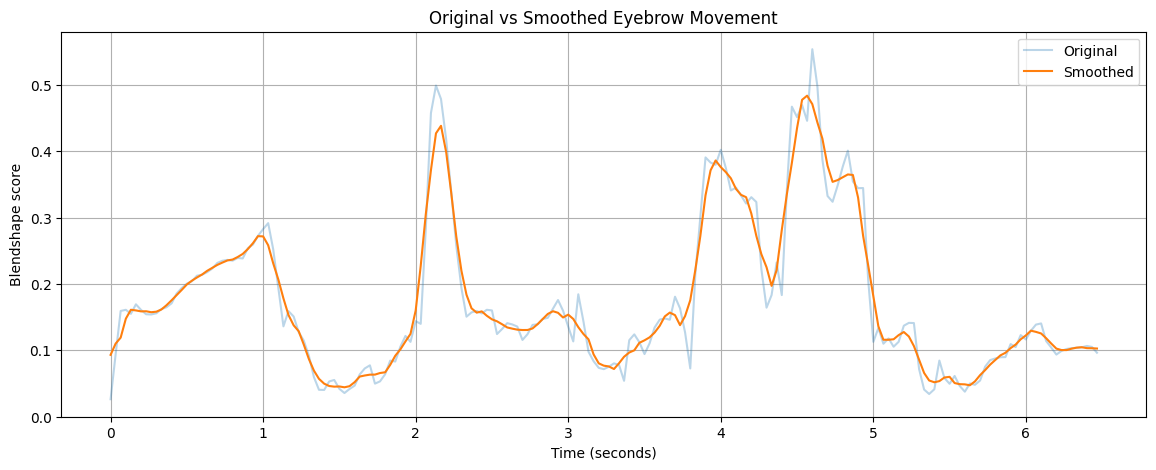

Missing face frames: 0
Missing eyebrow values: 0


In [21]:
if "blendshape_browInnerUp" in temporal_df.columns:
    temporal_df["browInnerUp_smoothed"] = (
        temporal_df["blendshape_browInnerUp"]
        .rolling(window=5, center=True, min_periods=1)
        .mean()
    )

    plt.figure(figsize=(14, 5))
    plt.plot(
        temporal_df["timestamp_ms"] / 1000,
        temporal_df["blendshape_browInnerUp"],
        alpha=0.3,
        label="Original"
    )
    plt.plot(
        temporal_df["timestamp_ms"] / 1000,
        temporal_df["browInnerUp_smoothed"],
        label="Smoothed"
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Blendshape score")
    plt.title("Original vs Smoothed Eyebrow Movement")
    plt.legend()
    plt.grid()
    plt.show()

print("Missing face frames:", int((~temporal_df["face_detected"]).sum()))
if "blendshape_browInnerUp" in temporal_df.columns:
    print(
        "Missing eyebrow values:",
        int(temporal_df["blendshape_browInnerUp"].isna().sum())
    )

# Extract Head-Pose Angles

In [22]:
head_pose_rows = []

cap = cv2.VideoCapture(video_path)

with FaceLandmarker.create_from_options(options) as landmarker:
    frame_index = 0

    while True:
        success, frame = cap.read()
        if not success:
            break

        timestamp_ms = int(frame_index * 1000 / fps)
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        result = landmarker.detect_for_video(mp_image, timestamp_ms)

        row = {
            "frame": frame_index,
            "timestamp_ms": timestamp_ms,
            "head_detected": len(result.face_landmarks) > 0,
            "head_pitch": np.nan,
            "head_yaw": np.nan,
            "head_roll": np.nan
        }

        if result.facial_transformation_matrixes:
            matrix = np.asarray(
                result.facial_transformation_matrixes[0],
                dtype=np.float64
            )

            if matrix.shape == (4, 4):
                rotation_matrix = matrix[:3, :3]

                # Convert the 3D rotation matrix into Euler angles.
                # 'zyx' returns angles in the order: yaw, pitch, roll.
                yaw, pitch, roll = Rotation.from_matrix(
                    rotation_matrix
                ).as_euler("zyx", degrees=True)

                row["head_yaw"] = yaw
                row["head_pitch"] = pitch
                row["head_roll"] = roll

        head_pose_rows.append(row)
        frame_index += 1

cap.release()

head_df = pd.DataFrame(head_pose_rows)

print("Head-pose extraction completed!")
print("Head-pose table shape:", head_df.shape)
print("Frames with head pose:", int(head_df["head_detected"].sum()))
display(head_df.head())

Head-pose extraction completed!
Head-pose table shape: (195, 6)
Frames with head pose: 195


,frame,timestamp_ms,head_detected,head_pitch,head_yaw,head_roll
0,0,0,True,6.739667,11.282486,-6.182987
1,1,33,True,4.345215,6.227983,-0.783460
2,2,66,True,3.773823,4.764062,-0.477785
3,3,100,True,3.805650,4.554701,-0.503090
4,4,133,True,3.703557,4.528473,-0.551478


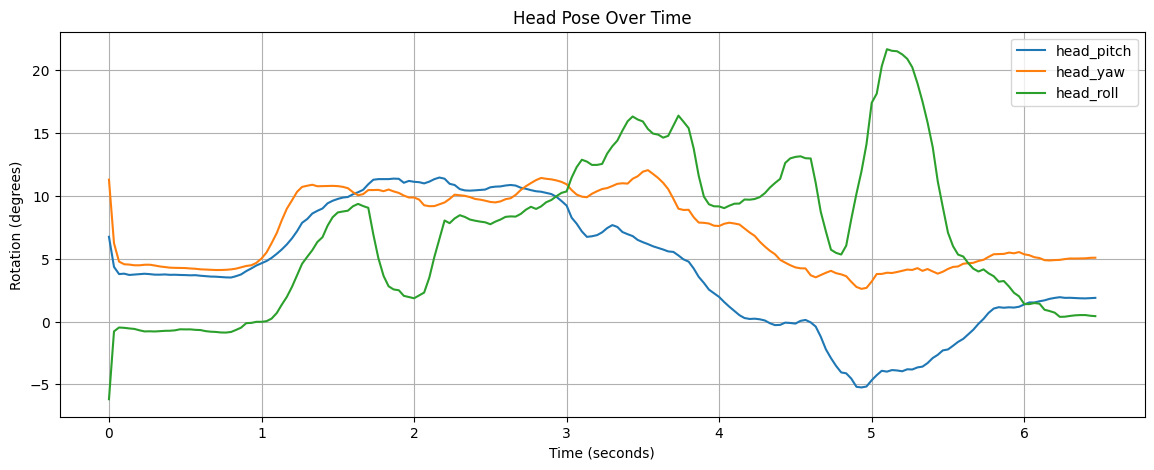

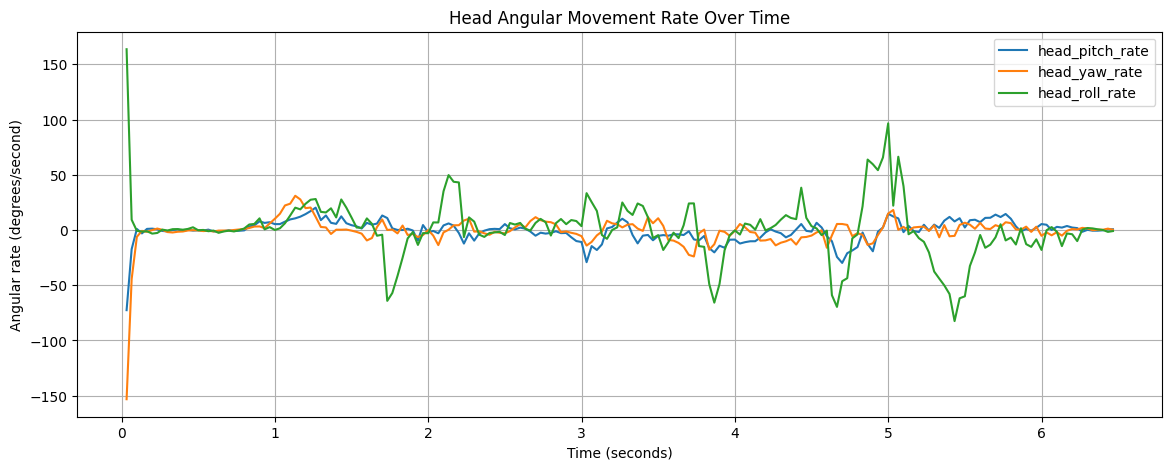

Head temporal features calculated!


In [23]:
head_angle_columns = ["head_pitch", "head_yaw", "head_roll"]

time_seconds = head_df["timestamp_ms"] / 1000
time_diff = time_seconds.diff().replace(0, np.nan)

for col in head_angle_columns:
    # Unwrap angles to avoid artificial jumps around +/-180 degrees.
    angles_rad = np.unwrap(np.deg2rad(head_df[col].to_numpy(dtype=float)))
    angles_deg = np.rad2deg(angles_rad)

    head_df[f"{col}_rate"] = (
        pd.Series(angles_deg, index=head_df.index).diff() / time_diff
    )

# Plot head orientation
plt.figure(figsize=(14, 5))
for col in head_angle_columns:
    plt.plot(
        head_df["timestamp_ms"] / 1000,
        head_df[col],
        label=col
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Rotation (degrees)")
plt.title("Head Pose Over Time")
plt.legend()
plt.grid()
plt.show()

# Plot angular movement rates
plt.figure(figsize=(14, 5))
for col in head_angle_columns:
    rate_col = f"{col}_rate"
    plt.plot(
        head_df["timestamp_ms"] / 1000,
        head_df[rate_col],
        label=rate_col
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Angular rate (degrees/second)")
plt.title("Head Angular Movement Rate Over Time")
plt.legend()
plt.grid()
plt.show()

print("Head temporal features calculated!")

In [24]:
head_columns = [
    "frame",
    "head_pitch",
    "head_yaw",
    "head_roll",
    "head_pitch_rate",
    "head_yaw_rate",
    "head_roll_rate"
]

facial_df = facial_df.merge(
    head_df[head_columns],
    on="frame",
    how="left"
)

print("Combined facial feature table shape:", facial_df.shape)
display(facial_df.head())

Combined facial feature table shape: (195, 27)


,frame,timestamp_ms,face_detected,blendshape_browInnerUp,blendshape_browDownLeft,blendshape_browDownRight,blendshape_browOuterUpLeft,blendshape_browOuterUpRight,blendshape_eyeBlinkLeft,blendshape_eyeBlinkRight,...,blendshape_mouthSmileLeft,blendshape_mouthSmileRight,blendshape_mouthPressLeft,blendshape_mouthPressRight,head_pitch,head_yaw,head_roll,head_pitch_rate,head_yaw_rate,head_roll_rate
0,0,0,True,0.026162,0.000368,0.086939,0.686218,0.007839,0.084780,0.525877,...,0.012799,0.053377,0.156517,0.621088,6.739667,11.282486,-6.182987,NaN,NaN,NaN
1,1,33,True,0.093760,0.015091,0.011320,0.070378,0.031080,0.455023,0.463987,...,0.000815,0.000618,0.143303,0.151159,4.345215,6.227983,-0.783460,-72.559137,-153.166769,163.622023
2,2,66,True,0.159248,0.009599,0.005767,0.090608,0.040310,0.393674,0.397619,...,0.000018,0.000011,0.036902,0.052354,3.773823,4.764062,-0.477785,-17.314909,-44.361238,9.262889
3,3,100,True,0.161017,0.008226,0.004930,0.105301,0.051751,0.347290,0.367081,...,0.000006,0.000003,0.029136,0.036000,3.805650,4.554701,-0.503090,0.936070,-6.157685,-0.744267
4,4,133,True,0.154933,0.008090,0.005287,0.109267,0.053804,0.331615,0.358266,...,0.000006,0.000003,0.029352,0.036500,3.703557,4.528473,-0.551478,-3.093707,-0.794774,-1.466305


# Build Facial Feature Sequence

In [25]:
feature_columns = [
    col for col in facial_df.columns
    if col.startswith("blendshape_")
    or col in [
        "head_pitch",
        "head_yaw",
        "head_roll",
        "head_pitch_rate",
        "head_yaw_rate",
        "head_roll_rate"
    ]
]

print("Number of selected facial features:", len(feature_columns))

X_face_df = facial_df[feature_columns].copy()

# Interpolate short gaps only; remaining gaps are filled with zero.
X_face_df = X_face_df.interpolate(
    method="linear",
    limit=5,
    limit_area="inside"
).fillna(0)

# Blendshape scores are expected to be in [0, 1].
blendshape_columns = [
    col for col in feature_columns
    if col.startswith("blendshape_")
]
X_face_df[blendshape_columns] = X_face_df[blendshape_columns].clip(0, 1)

X_face = X_face_df.to_numpy(dtype=np.float32)

# Keep the detection mask separate so the model can identify missing-face frames.
face_mask = facial_df["face_detected"].to_numpy(dtype=np.float32)

print("Missing values:", np.isnan(X_face).sum())
print("Facial sequence shape:", X_face.shape)
print("Face mask shape:", face_mask.shape)
print("Feature names:", feature_columns)

Number of selected facial features: 24
Missing values: 0
Facial sequence shape: (195, 24)
Face mask shape: (195,)
Feature names: ['blendshape_browInnerUp', 'blendshape_browDownLeft', 'blendshape_browDownRight', 'blendshape_browOuterUpLeft', 'blendshape_browOuterUpRight', 'blendshape_eyeBlinkLeft', 'blendshape_eyeBlinkRight', 'blendshape_eyeWideLeft', 'blendshape_eyeWideRight', 'blendshape_eyeSquintLeft', 'blendshape_eyeSquintRight', 'blendshape_jawOpen', 'blendshape_mouthFunnel', 'blendshape_mouthPucker', 'blendshape_mouthSmileLeft', 'blendshape_mouthSmileRight', 'blendshape_mouthPressLeft', 'blendshape_mouthPressRight', 'head_pitch', 'head_yaw', 'head_roll', 'head_pitch_rate', 'head_yaw_rate', 'head_roll_rate']


In [27]:
np.save("X_face.npy", X_face)
np.save("face_mask.npy", face_mask)

facial_df.to_csv("complete_facial_features.csv", index=False)

print("Saved successfully!")
print("Final facial sequence:", X_face.shape)
print("Final face mask:", face_mask.shape)
print("Data type:", X_face.dtype)

files.download("X_face.npy")
files.download("face_mask.npy")
files.download("complete_facial_features.csv")

Saved successfully!
Final facial sequence: (195, 24)
Final face mask: (195,)
Data type: float32


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>